# Лабораторна робота № 2

## Оптимізаційна задача та аналіз чутливості

**Дисципліна:** Інтелектуальний аналіз та візуалізація даних (СК26)
**Тривалість:** 2 год аудиторно + 3 год самостійної роботи · **Максимальна оцінка:** 4 бали

---

### Мета роботи

Побудувати оптимізаційну модель у двох середовищах, прочитати звіт про стійкість
і **ухвалити на його основі господарське рішення**.

Розв'язати задачу — не мета. Solver зробить це за дві секунди. Робота оцінюється за
те, що ви зумієте зі звіту витягнути.

### Дві частини

| Частина | Задача | Де виконується |
|---|---|---|
| **1** | виробнича задача — Excel і Python | аудиторно |
| **2** | транспортна задача — Python | самостійно |

Друга частина потрібна не для повторення. Там та сама методика поводиться інакше,
і ви маєте побачити, де саме проходить межа її застосовності.

### Що здається

1. Цей файл `.ipynb` із заповненими розв'язками. **Виконується згори донизу на чистому
   ядрі** (Kernel → Restart & Run All) без помилок — перевіряється першою дією на захисті.
2. Файл Excel з моделлю, налаштуваннями Solver і **звітом про стійкість** окремим аркушем.
3. Заповнена декларація про використання ШІ (етап 12).

### Оцінювання

| Бали | Що досягнуто |
|---|---|
| 0 | Модель не сформульовано або розв'язок не отримано |
| 1 | Розв'язок отримано лише в одному середовищі, звіт про стійкість не проаналізовано |
| 2 | Задачу розв'язано в обох середовищах і звіти зіставлено, але тіньові ціни та діапазони не інтерпретовано |
| 4 | Звіт прочитано й перевірено експериментом, ухвалено обґрунтоване рішення про закупівлю, виконано частину 2 з поясненням розбіжності |

---
## Крок 0. Ваші дані та варіант

In [1]:
ПІБ = 'Козак Наталія Володимирівна'        # напр. 'Шевченко Тарас'
ГРУПА = 'ШІ-34'      # напр. 'КН-31'
ВАРІАНТ = 6     # ваш номер за списком групи

assert ПІБ and ГРУПА and 1 <= ВАРІАНТ <= 30, 'Заповніть ПІБ, ГРУПУ та ВАРІАНТ (1..30)'

In [2]:
# --- клітинку не редагувати: вона видає дані вашого варіанта -----------------
import json, numpy as np, pandas as pd

ДАНІ_ВАРІАНТІВ = json.loads('''{"1": {"фірма": "«Астро-ТВ»", "що": "телевізори", "од": "шт./день", "вироби": ["Astro", "Cosmo", "Nova", "Vega"], "ресурси": ["Конвеєр A, год", "Конвеєр Б, год", "Цех кінескопів, год", "Цех корпусів, год", "Ділянка збирання, год"], "A": [[0, 2, 1, 1], [3, 3, 0, 6], [2, 3, 0, 2], [4, 6, 0, 5], [3, 1, 5, 4]], "c": [21, 69, 44, 39], "b": [929, 410, 507, 865, 425], "ресурс_пропозиції": 1, "ціна_пропозиції": 16.2, "обсяг_пропозиції": 44}, "2": {"фірма": "«Longer Boats»", "що": "яхти", "од": "шт./місяць", "вироби": ["Sting", "Ray", "Breaker", "Marlin"], "ресурси": ["Склопластик, м²", "Столярний цех, год", "Фарбувальний цех, год", "Такелаж, компл.", "Ділянка добудови, год"], "A": [[4, 2, 5, 2], [6, 5, 4, 2], [5, 2, 0, 3], [2, 1, 5, 0], [5, 5, 6, 2]], "c": [40, 66, 24, 34], "b": [1271, 702, 915, 1388, 804], "ресурс_пропозиції": 1, "ціна_пропозиції": 16.7, "обсяг_пропозиції": 204}, "3": {"фірма": "«Карпатський дуб»", "що": "меблі", "од": "шт./тиждень", "вироби": ["Крісло", "Стілець", "Табурет", "Лава"], "ресурси": ["Дубовий брус, м", "Фанера, м²", "Фурнітура, компл.", "Верстат, год", "Лакування, год"], "A": [[5, 2, 6, 6], [3, 4, 3, 6], [1, 6, 6, 0], [3, 1, 6, 1], [4, 1, 1, 4]], "c": [51, 16, 34, 22], "b": [1189, 686, 1311, 512, 1030], "ресурс_пропозиції": 3, "ціна_пропозиції": 11.3, "обсяг_пропозиції": 348}, "4": {"фірма": "«Друк-Сервіс»", "що": "поліграфію", "од": "тис. прим./тиждень", "вироби": ["Буклет", "Каталог", "Календар", "Плакат"], "ресурси": ["Крейдований папір, кг", "Офсетний папір, кг", "Фарба, кг", "Друкарська машина, год", "Різка й фальцювання, год"], "A": [[5, 0, 0, 0], [1, 0, 5, 2], [2, 4, 6, 5], [3, 0, 5, 3], [2, 1, 2, 5]], "c": [41, 50, 54, 26], "b": [815, 344, 840, 840, 382], "ресурс_пропозиції": 4, "ціна_пропозиції": 8.3, "обсяг_пропозиції": 144}, "5": {"фірма": "«Астро-ТВ»", "що": "телевізори", "од": "шт./день", "вироби": ["Astro", "Cosmo", "Nova", "Vega"], "ресурси": ["Конвеєр A, год", "Конвеєр Б, год", "Цех кінескопів, год", "Цех корпусів, год", "Ділянка збирання, год"], "A": [[3, 0, 6, 6], [3, 2, 2, 4], [5, 5, 0, 6], [2, 1, 5, 3], [5, 5, 4, 2]], "c": [32, 66, 25, 24], "b": [874, 1034, 1349, 845, 1394], "ресурс_пропозиції": 2, "ціна_пропозиції": 8.6, "обсяг_пропозиції": 90}, "6": {"фірма": "«Longer Boats»", "що": "яхти", "од": "шт./місяць", "вироби": ["Sting", "Ray", "Breaker", "Marlin"], "ресурси": ["Склопластик, м²", "Столярний цех, год", "Фарбувальний цех, год", "Такелаж, компл.", "Ділянка добудови, год"], "A": [[3, 2, 1, 4], [4, 2, 2, 1], [3, 5, 1, 2], [3, 2, 0, 2], [6, 4, 6, 3]], "c": [40, 62, 19, 57], "b": [630, 391, 1349, 811, 1085], "ресурс_пропозиції": 1, "ціна_пропозиції": 29.5, "обсяг_пропозиції": 268}, "7": {"фірма": "«Карпатський дуб»", "що": "меблі", "од": "шт./тиждень", "вироби": ["Крісло", "Стілець", "Табурет", "Лава"], "ресурси": ["Дубовий брус, м", "Фанера, м²", "Фурнітура, компл.", "Верстат, год", "Лакування, год"], "A": [[0, 0, 5, 5], [4, 4, 0, 1], [2, 4, 0, 6], [6, 3, 4, 1], [2, 2, 1, 0]], "c": [20, 59, 63, 41], "b": [1189, 1189, 1217, 915, 424], "ресурс_пропозиції": 3, "ціна_пропозиції": 8.0, "обсяг_пропозиції": 314}, "8": {"фірма": "«Друк-Сервіс»", "що": "поліграфію", "од": "тис. прим./тиждень", "вироби": ["Буклет", "Каталог", "Календар", "Плакат"], "ресурси": ["Крейдований папір, кг", "Офсетний папір, кг", "Фарба, кг", "Друкарська машина, год", "Різка й фальцювання, год"], "A": [[2, 1, 3, 5], [3, 1, 0, 6], [1, 6, 1, 5], [2, 2, 4, 0], [6, 1, 2, 2]], "c": [60, 25, 59, 25], "b": [1279, 761, 376, 1230, 1065], "ресурс_пропозиції": 3, "ціна_пропозиції": 9.5, "обсяг_пропозиції": 234}, "9": {"фірма": "«Астро-ТВ»", "що": "телевізори", "од": "шт./день", "вироби": ["Astro", "Cosmo", "Nova", "Vega"], "ресурси": ["Конвеєр A, год", "Конвеєр Б, год", "Цех кінескопів, год", "Цех корпусів, год", "Ділянка збирання, год"], "A": [[5, 2, 1, 2], [5, 0, 1, 3], [5, 4, 6, 4], [4, 1, 1, 5], [6, 0, 3, 0]], "c": [58, 39, 54, 16], "b": [1147, 1199, 1280, 404, 1170], "ресурс_пропозиції": 2, "ціна_пропозиції": 6.1, "обсяг_пропозиції": 672}, "10": {"фірма": "«Longer Boats»", "що": "яхти", "од": "шт./місяць", "вироби": ["Sting", "Ray", "Breaker", "Marlin"], "ресурси": ["Склопластик, м²", "Столярний цех, год", "Фарбувальний цех, год", "Такелаж, компл.", "Ділянка добудови, год"], "A": [[4, 0, 4, 3], [0, 6, 0, 6], [5, 5, 3, 5], [6, 2, 3, 3], [3, 0, 0, 4]], "c": [20, 29, 37, 63], "b": [905, 344, 866, 1390, 355], "ресурс_пропозиції": 0, "ціна_пропозиції": 5.3, "обсяг_пропозиції": 78}, "11": {"фірма": "«Карпатський дуб»", "що": "меблі", "од": "шт./тиждень", "вироби": ["Крісло", "Стілець", "Табурет", "Лава"], "ресурси": ["Дубовий брус, м", "Фанера, м²", "Фурнітура, компл.", "Верстат, год", "Лакування, год"], "A": [[2, 1, 0, 3], [3, 1, 4, 0], [1, 0, 3, 2], [3, 2, 2, 6], [3, 6, 0, 3]], "c": [30, 16, 51, 35], "b": [1312, 838, 1062, 1038, 1236], "ресурс_пропозиції": 1, "ціна_пропозиції": 15.6, "обсяг_пропозиції": 778}, "12": {"фірма": "«Друк-Сервіс»", "що": "поліграфію", "од": "тис. прим./тиждень", "вироби": ["Буклет", "Каталог", "Календар", "Плакат"], "ресурси": ["Крейдований папір, кг", "Офсетний папір, кг", "Фарба, кг", "Друкарська машина, год", "Різка й фальцювання, год"], "A": [[5, 2, 0, 5], [1, 1, 3, 6], [6, 3, 5, 4], [2, 4, 6, 0], [4, 6, 2, 4]], "c": [39, 55, 36, 26], "b": [788, 661, 458, 1005, 535], "ресурс_пропозиції": 4, "ціна_пропозиції": 5.0, "обсяг_пропозиції": 762}, "13": {"фірма": "«Астро-ТВ»", "що": "телевізори", "од": "шт./день", "вироби": ["Astro", "Cosmo", "Nova", "Vega"], "ресурси": ["Конвеєр A, год", "Конвеєр Б, год", "Цех кінескопів, год", "Цех корпусів, год", "Ділянка збирання, год"], "A": [[1, 5, 3, 0], [6, 4, 6, 3], [4, 4, 4, 1], [0, 3, 5, 3], [3, 5, 3, 3]], "c": [59, 42, 53, 19], "b": [937, 1390, 603, 1120, 1334], "ресурс_пропозиції": 2, "ціна_пропозиції": 15.1, "обсяг_пропозиції": 646}, "14": {"фірма": "«Longer Boats»", "що": "яхти", "од": "шт./місяць", "вироби": ["Sting", "Ray", "Breaker", "Marlin"], "ресурси": ["Склопластик, м²", "Столярний цех, год", "Фарбувальний цех, год", "Такелаж, компл.", "Ділянка добудови, год"], "A": [[4, 3, 3, 4], [6, 6, 1, 6], [1, 3, 5, 1], [1, 5, 1, 4], [4, 4, 0, 3]], "c": [26, 56, 41, 40], "b": [969, 672, 1364, 878, 618], "ресурс_пропозиції": 2, "ціна_пропозиції": 5.0, "обсяг_пропозиції": 222}, "15": {"фірма": "«Карпатський дуб»", "що": "меблі", "од": "шт./тиждень", "вироби": ["Крісло", "Стілець", "Табурет", "Лава"], "ресурси": ["Дубовий брус, м", "Фанера, м²", "Фурнітура, компл.", "Верстат, год", "Лакування, год"], "A": [[5, 3, 3, 1], [2, 5, 6, 6], [3, 1, 0, 0], [0, 4, 4, 6], [2, 2, 2, 6]], "c": [64, 58, 34, 63], "b": [613, 316, 1035, 739, 810], "ресурс_пропозиції": 0, "ціна_пропозиції": 5.4, "обсяг_пропозиції": 354}, "16": {"фірма": "«Друк-Сервіс»", "що": "поліграфію", "од": "тис. прим./тиждень", "вироби": ["Буклет", "Каталог", "Календар", "Плакат"], "ресурси": ["Крейдований папір, кг", "Офсетний папір, кг", "Фарба, кг", "Друкарська машина, год", "Різка й фальцювання, год"], "A": [[1, 6, 4, 2], [4, 1, 1, 2], [4, 4, 6, 6], [5, 6, 3, 3], [1, 2, 4, 2]], "c": [33, 40, 58, 17], "b": [412, 1005, 996, 599, 390], "ресурс_пропозиції": 4, "ціна_пропозиції": 8.2, "обсяг_пропозиції": 44}, "17": {"фірма": "«Астро-ТВ»", "що": "телевізори", "од": "шт./день", "вироби": ["Astro", "Cosmo", "Nova", "Vega"], "ресурси": ["Конвеєр A, год", "Конвеєр Б, год", "Цех кінескопів, год", "Цех корпусів, год", "Ділянка збирання, год"], "A": [[2, 6, 0, 3], [2, 5, 5, 3], [6, 0, 4, 5], [1, 3, 6, 2], [0, 1, 4, 4]], "c": [33, 52, 20, 66], "b": [989, 1079, 873, 1327, 1224], "ресурс_пропозиції": 0, "ціна_пропозиції": 5.9, "обсяг_пропозиції": 402}, "18": {"фірма": "«Longer Boats»", "що": "яхти", "од": "шт./місяць", "вироби": ["Sting", "Ray", "Breaker", "Marlin"], "ресурси": ["Склопластик, м²", "Столярний цех, год", "Фарбувальний цех, год", "Такелаж, компл.", "Ділянка добудови, год"], "A": [[2, 3, 0, 1], [0, 6, 1, 6], [1, 0, 4, 1], [2, 6, 3, 4], [3, 1, 6, 5]], "c": [66, 54, 18, 66], "b": [1217, 668, 923, 1040, 619], "ресурс_пропозиції": 4, "ціна_пропозиції": 34.9, "обсяг_пропозиції": 100}, "19": {"фірма": "«Карпатський дуб»", "що": "меблі", "од": "шт./тиждень", "вироби": ["Крісло", "Стілець", "Табурет", "Лава"], "ресурси": ["Дубовий брус, м", "Фанера, м²", "Фурнітура, компл.", "Верстат, год", "Лакування, год"], "A": [[2, 1, 0, 2], [3, 3, 4, 5], [2, 1, 0, 4], [4, 1, 5, 0], [0, 3, 6, 3]], "c": [67, 52, 41, 40], "b": [315, 617, 815, 423, 1193], "ресурс_пропозиції": 1, "ціна_пропозиції": 9.3, "обсяг_пропозиції": 332}, "20": {"фірма": "«Друк-Сервіс»", "що": "поліграфію", "од": "тис. прим./тиждень", "вироби": ["Буклет", "Каталог", "Календар", "Плакат"], "ресурси": ["Крейдований папір, кг", "Офсетний папір, кг", "Фарба, кг", "Друкарська машина, год", "Різка й фальцювання, год"], "A": [[5, 4, 5, 1], [2, 0, 5, 4], [4, 0, 2, 3], [3, 3, 4, 3], [4, 4, 5, 2]], "c": [42, 63, 35, 56], "b": [1191, 331, 685, 1275, 971], "ресурс_пропозиції": 4, "ціна_пропозиції": 12.2, "обсяг_пропозиції": 604}, "21": {"фірма": "«Астро-ТВ»", "що": "телевізори", "од": "шт./день", "вироби": ["Astro", "Cosmo", "Nova", "Vega"], "ресурси": ["Конвеєр A, год", "Конвеєр Б, год", "Цех кінескопів, год", "Цех корпусів, год", "Ділянка збирання, год"], "A": [[5, 5, 3, 6], [4, 4, 3, 2], [4, 4, 4, 0], [1, 1, 5, 3], [0, 2, 6, 5]], "c": [32, 66, 26, 64], "b": [464, 393, 354, 597, 887], "ресурс_пропозиції": 0, "ціна_пропозиції": 9.4, "обсяг_пропозиції": 190}, "22": {"фірма": "«Longer Boats»", "що": "яхти", "од": "шт./місяць", "вироби": ["Sting", "Ray", "Breaker", "Marlin"], "ресурси": ["Склопластик, м²", "Столярний цех, год", "Фарбувальний цех, год", "Такелаж, компл.", "Ділянка добудови, год"], "A": [[6, 0, 2, 6], [3, 4, 0, 4], [4, 3, 1, 5], [5, 5, 6, 2], [2, 0, 1, 5]], "c": [65, 36, 50, 63], "b": [891, 1247, 613, 1070, 1259], "ресурс_пропозиції": 2, "ціна_пропозиції": 13.6, "обсяг_пропозиції": 64}, "23": {"фірма": "«Карпатський дуб»", "що": "меблі", "од": "шт./тиждень", "вироби": ["Крісло", "Стілець", "Табурет", "Лава"], "ресурси": ["Дубовий брус, м", "Фанера, м²", "Фурнітура, компл.", "Верстат, год", "Лакування, год"], "A": [[1, 2, 4, 6], [4, 6, 2, 5], [0, 5, 3, 1], [0, 0, 5, 1], [5, 4, 0, 5]], "c": [15, 35, 49, 23], "b": [1251, 637, 304, 629, 923], "ресурс_пропозиції": 2, "ціна_пропозиції": 10.9, "обсяг_пропозиції": 146}, "24": {"фірма": "«Друк-Сервіс»", "що": "поліграфію", "од": "тис. прим./тиждень", "вироби": ["Буклет", "Каталог", "Календар", "Плакат"], "ресурси": ["Крейдований папір, кг", "Офсетний папір, кг", "Фарба, кг", "Друкарська машина, год", "Різка й фальцювання, год"], "A": [[3, 2, 6, 1], [0, 2, 5, 6], [2, 4, 4, 0], [5, 6, 2, 5], [2, 4, 2, 1]], "c": [45, 61, 59, 38], "b": [927, 1384, 1294, 798, 323], "ресурс_пропозиції": 4, "ціна_пропозиції": 20.5, "обсяг_пропозиції": 110}, "25": {"фірма": "«Астро-ТВ»", "що": "телевізори", "од": "шт./день", "вироби": ["Astro", "Cosmo", "Nova", "Vega"], "ресурси": ["Конвеєр A, год", "Конвеєр Б, год", "Цех кінескопів, год", "Цех корпусів, год", "Ділянка збирання, год"], "A": [[5, 5, 4, 4], [2, 1, 4, 1], [3, 1, 4, 4], [1, 4, 2, 0], [6, 4, 6, 6]], "c": [35, 27, 63, 61], "b": [1399, 843, 308, 1393, 713], "ресурс_пропозиції": 2, "ціна_пропозиції": 7.7, "обсяг_пропозиції": 334}, "26": {"фірма": "«Longer Boats»", "що": "яхти", "од": "шт./місяць", "вироби": ["Sting", "Ray", "Breaker", "Marlin"], "ресурси": ["Склопластик, м²", "Столярний цех, год", "Фарбувальний цех, год", "Такелаж, компл.", "Ділянка добудови, год"], "A": [[4, 1, 4, 4], [3, 1, 5, 0], [6, 3, 6, 3], [1, 3, 6, 1], [6, 4, 5, 2]], "c": [46, 57, 60, 39], "b": [513, 1330, 796, 406, 1258], "ресурс_пропозиції": 3, "ціна_пропозиції": 18.1, "обсяг_пропозиції": 448}, "27": {"фірма": "«Карпатський дуб»", "що": "меблі", "од": "шт./тиждень", "вироби": ["Крісло", "Стілець", "Табурет", "Лава"], "ресурси": ["Дубовий брус, м", "Фанера, м²", "Фурнітура, компл.", "Верстат, год", "Лакування, год"], "A": [[2, 1, 6, 0], [6, 5, 6, 0], [5, 2, 3, 0], [6, 4, 3, 6], [6, 0, 0, 3]], "c": [24, 61, 50, 57], "b": [1179, 1358, 417, 463, 610], "ресурс_пропозиції": 3, "ціна_пропозиції": 9.0, "обсяг_пропозиції": 742}, "28": {"фірма": "«Друк-Сервіс»", "що": "поліграфію", "од": "тис. прим./тиждень", "вироби": ["Буклет", "Каталог", "Календар", "Плакат"], "ресурси": ["Крейдований папір, кг", "Офсетний папір, кг", "Фарба, кг", "Друкарська машина, год", "Різка й фальцювання, год"], "A": [[4, 5, 6, 2], [6, 4, 2, 1], [0, 5, 4, 3], [6, 6, 3, 3], [4, 4, 4, 1]], "c": [37, 41, 30, 29], "b": [514, 461, 378, 834, 488], "ресурс_пропозиції": 2, "ціна_пропозиції": 5.5, "обсяг_пропозиції": 174}, "29": {"фірма": "«Астро-ТВ»", "що": "телевізори", "од": "шт./день", "вироби": ["Astro", "Cosmo", "Nova", "Vega"], "ресурси": ["Конвеєр A, год", "Конвеєр Б, год", "Цех кінескопів, год", "Цех корпусів, год", "Ділянка збирання, год"], "A": [[3, 5, 0, 5], [6, 0, 6, 1], [5, 2, 2, 3], [0, 3, 0, 1], [4, 5, 5, 0]], "c": [33, 57, 58, 62], "b": [820, 523, 670, 977, 1074], "ресурс_пропозиції": 0, "ціна_пропозиції": 15.2, "обсяг_пропозиції": 570}, "30": {"фірма": "«Longer Boats»", "що": "яхти", "од": "шт./місяць", "вироби": ["Sting", "Ray", "Breaker", "Marlin"], "ресурси": ["Склопластик, м²", "Столярний цех, год", "Фарбувальний цех, год", "Такелаж, компл.", "Ділянка добудови, год"], "A": [[2, 1, 4, 0], [6, 5, 1, 4], [5, 6, 1, 4], [1, 2, 6, 0], [1, 0, 3, 1]], "c": [51, 44, 69, 55], "b": [379, 620, 1256, 502, 414], "ресурс_пропозиції": 1, "ціна_пропозиції": 16.9, "обсяг_пропозиції": 230}}''')

V = ДАНІ_ВАРІАНТІВ[str(ВАРІАНТ)]
A = np.array(V['A'], float)          # витрати ресурсу i на один виріб j
c = np.array(V['c'], float)          # прибуток з одного виробу
b = np.array(V['b'], float)          # запас ресурсу на плановий період
вироби, ресурси = V['вироби'], V['ресурси']

print('ВАРІАНТ %d · %s, %s, %s' % (ВАРІАНТ, ПІБ, ГРУПА, V['фірма']))
print('=' * 78)
print('Підприємство %s виготовляє %s. Одиниця виміру плану: %s.' % (V['фірма'], V['що'], V['од']))
print()
таб = pd.DataFrame(A, index=ресурси, columns=вироби).astype(int)
таб['ЗАПАС'] = b.astype(int)
print(таб.to_string())
print()
print(pd.DataFrame([c.astype(int)], index=['Прибуток з одиниці'], columns=вироби).to_string())
print()
print('ПРОПОЗИЦІЯ ПОСТАЧАЛЬНИКА (знадобиться на етапі 6)')
print('  ресурс: %s' % ресурси[V['ресурс_пропозиції']])
print('  ціна:   %.1f за одиницю' % V['ціна_пропозиції'])
print('  обсяг:  до %d одиниць' % V['обсяг_пропозиції'])

ВАРІАНТ 6 · Козак Наталія Володимирівна, ШІ-34, «Longer Boats»
Підприємство «Longer Boats» виготовляє яхти. Одиниця виміру плану: шт./місяць.

                       Sting  Ray  Breaker  Marlin  ЗАПАС
Склопластик, м²            3    2        1       4    630
Столярний цех, год         4    2        2       1    391
Фарбувальний цех, год      3    5        1       2   1349
Такелаж, компл.            3    2        0       2    811
Ділянка добудови, год      6    4        6       3   1085

                    Sting  Ray  Breaker  Marlin
Прибуток з одиниці     40   62       19      57

ПРОПОЗИЦІЯ ПОСТАЧАЛЬНИКА (знадобиться на етапі 6)
  ресурс: Столярний цех, год
  ціна:   29.5 за одиницю
  обсяг:  до 268 одиниць


In [3]:
import matplotlib.pyplot as plt
try:
    import pulp
    ПУЛП = True
except ImportError:
    ПУЛП = False
    print('pulp не встановлено — скористайтеся scipy.optimize.linprog')
from scipy.optimize import linprog

pd.set_option('display.width', 180)
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False,
                     'axes.spines.right': False, 'font.size': 9})

---
# ЧАСТИНА 1. Виробнича задача

# Етап 1. Формалізація

Перш ніж будувати таблицю, запишіть модель словами й формулами. Це найважливіші
двадцять хвилин роботи: помилку тут не виправить жодна кнопка.

### Завдання 1.1
Заповніть у клітинці нижче:

* **змінні рішення** — що саме ви обираєте і в яких одиницях;
* **цільова функція** — що робите найбільшим, з коефіцієнтами вашого варіанта;
* **обмеження** — по одному рядку на кожен ресурс, з числами вашого варіанта;
* **умови невід'ємності**.

Пишіть формулами, а не описом. Приклад запису одного обмеження:
`8·x1 + 4·x2 + 0·x3 + 2·x4 ≤ 1280   (конвеєр A)`

**Відповідь 1.1 - символічна модель**

Змінні рішення:

x1 - кількість яхт Sting, x2 - кількість яхт Ray, x3 - кількість яхт Breaker, x4 - кількість яхт Marlin, шт./місяць

Цільова функція:

Z = 40·x1 + 62·x2 + 19·x3 + 57·x4 → max

Обмеження:

3·x1 + 2·x2 + 1·x3 + 4·x4 ≤ 630   (склопластик, м²)

4·x1 + 2·x2 + 2·x3 + 1·x4 ≤ 391   (столярний цех, год)

3·x1 + 5·x2 + 1·x3 + 2·x4 ≤ 1349  (фарбувальний цех, год)

3·x1 + 2·x2 + 0·x3 + 2·x4 ≤ 811   (такелаж, компл.)

6·x1 + 4·x2 + 6·x3 + 3·x4 ≤ 1085  (ділянка добудови, год)

Невід'ємність:

x1, x2, x3, x4 ≥ 0


### Завдання 1.2 — питання на розуміння
Чому запас ресурсу — це **параметр**, а не змінна рішення? Що змінилося б у моделі,
якби підприємство могло докупити ресурс у будь-якій кількості?

**Відповідь 1.2:**

b - це запас кожного ресурсу (стовпець "ЗАПАС" у таблиці варіанта: скло, час цехів, такелаж тощо). Це параметр, бо підприємство його не обирає - обсяг заданий ззовні на плановий період. Змінні рішення - це x1...x4, план випуску, яким підприємство керує; b - лише умова, в межах якої цей план обирається.

Якщо докупити в будь-якій кількості можна лише **один** ресурс (за ціною постачальника), обсяг такої закупівлі сам стає новою змінною, а її вартість входить у цільову функцію. Докуповувати вигідно, лише поки тіньова ціна цього ресурсу вища за ціну закупівлі. Але щойно його стає достатньо, випуск починає обмежувати вже інший ресурс - тіньова ціна першого падає до ціни закупівлі (чи до нуля), і подальша закупівля сенсу не має. Прибуток зростає, але до певної межі.

Якщо ж докупити в будь-якій кількості можна **всі п'ять** ресурсів одразу, ситуація інша: жоден ресурс більше не обмежує випуск, усі обмеження зникають. Якщо додатково ресурси ще й безкоштовні - задача стає необмеженою, прибуток можна нарощувати без кінця. Якщо ж вони не безкоштовні, а купуються за цінами постачальників - прибуток лишається скінченним доти, доки хоча б для одного виробу дохід з одиниці не перевищує вартість ресурсів, потрібних на цю одиницю; якщо перевищує - знову виходить необмежена задача, бо такий виріб вигідно робити нескінченно багато.

---
# Етап 2. Розв'язання в Excel

1. Побудуйте табличну модель: окремо клітинки змінних рішення, окремо витрати ресурсів,
   окремо цільова функція. Не змішуйте вхідні дані з формулами.
2. Налаштуйте **Пошук рішення (Solver)**: цільова клітинка на максимум, клітинки змінних,
   обмеження по кожному ресурсу, невід'ємність, метод «Симплекс-метод для лінійних задач».
3. Отримайте розв'язок і **обов'язково замовте «Звіт про стійкість»** окремим аркушем.

**Що подати:** файл Excel зі скріншотом налаштувань Solver, оптимальним планом і звітом.

### Завдання 2.1
Перенесіть результат Excel у клітинку нижче — його порівняємо з Python.

In [4]:
# впишіть числа, які дав Excel
EXCEL_ПЛАН    = [0, 155.6666667, 0, 79.66666667]     # оптимальний випуск кожного виробу
EXCEL_ПРИБУТОК = 14192.33333            # значення цільової функції

print('Excel:', EXCEL_ПЛАН, '| прибуток', EXCEL_ПРИБУТОК)

Excel: [0, 155.6666667, 0, 79.66666667] | прибуток 14192.33333


---
# Етап 3. Розв'язання в Python

### Завдання 3.1
Побудуйте ту саму модель у Python і розв'яжіть її. Можна `pulp`, можна
`scipy.optimize.linprog` — на ваш вибір.

*Очікуваний результат: оптимальний план і значення цільової функції.*

**Увага на знак.** `linprog` завжди мінімізує. Щоб максимізувати прибуток, передають
`-c`, а результат беруть як `-r.fun`.

In [5]:
# ВАШ КОД
from scipy.optimize import linprog

res = linprog(-c, A_ub=A, b_ub=b, bounds=[(0, None)] * len(c), method='highs')

план = list(res.x)
прибуток = -res.fun

print('план:', [round(x, 2) for x in план])
print('прибуток:', round(прибуток, 2))

план: [np.float64(0.0), np.float64(155.67), np.float64(0.0), np.float64(79.67)]
прибуток: 14192.33


**Самоперевірка етапу 3.** Excel і Python мають дати той самий результат.

In [6]:
assert план is not None and прибуток is not None, 'спершу розв’яжіть задачу'
assert abs(прибуток - EXCEL_ПРИБУТОК) < 0.5, (
    'Excel дав %.2f, Python %.2f — знайдіть, де розбіжність' % (EXCEL_ПРИБУТОК, прибуток))
assert np.allclose(np.array(план, float), np.array(EXCEL_ПЛАН, float), atol=0.5), \
    'плани не збігаються — перевірте обмеження'
print('Етап 3 пройдено: обидва середовища дали однаковий результат')

Етап 3 пройдено: обидва середовища дали однаковий результат


---
# Етап 4. Читання звіту про стійкість

Звіт Excel має два блоки. Заповніть обидві таблиці — беріть числа зі **звіту**,
а не з власних обчислень.

### Завдання 4.1 — блок «Обмеження»

| Ресурс | Кінцеве значення | Тіньова ціна | Права частина | Допустиме збільшення | Допустиме зменшення |
|---|---|---|---|---|---|
| Склопластик, м² | 630,00 | 8,67 | 630 | 670,00 | 239,00 |
| Столярний цех, год | 391,00 | 22,33 | 391 | 134,00 | 233,50 |
| Фарбувальний цех, год | 937,67 | 0 | 1349 | 1E+30 | 411,33 |
| Такелаж, компл. | 470,67 | 0 | 811 | 1E+30 | 340,33 |
| Ділянка добудови, год | 861,67 | 0 | 1085 | 1E+30 | 223,33 |

**Які ресурси в дефіциті, а які в надлишку? Як ви це визначили?**

У дефіциті - склопластик і столярний цех: їхнє кінцеве значення дорівнює правій частині (ресурс витрачено повністю), і тіньова ціна ненульова (8,67 і 22,33 відповідно) - кожна додаткова одиниця цих ресурсів реально збільшила б прибуток.

У надлишку - фарбувальний цех, такелаж і ділянка добудови: кінцеве значення менше за запас (наприклад, фарбувального цеху витрачено 937,67 з 1349), тіньова ціна дорівнює нулю - зайва одиниця цих ресурсів нічого б не додала до прибутку, бо виробництво впирається не в них.

### Завдання 4.2 — блок «Змінні»

| Виріб | Кінцеве значення | Зведена вартість | Цільовий коефіцієнт | Допустиме збільшення | Допустиме зменшення |
|---|---|---|---|---|---|
| Sting | 0,00 | -75,33 | 40 | 75,33 | 1E+30 |
| Ray | 155,67 | 0,00 | 62 | 52,00 | 29,43 |
| Breaker | 0,00 | -34,33 | 19 | 34,33 | 1E+30 |
| Marlin | 79,67 | 0,00 | 57 | 67,00 | 26,00 |

**У вашому варіанті принаймні один виріб не виробляється зовсім.**
Який саме, і на скільки мусив би зрости прибуток з його одиниці, щоб він увійшов у план?
Звідки ви взяли це число?

У плані взагалі відсутні два вироби - Sting і Breaker (кінцеве значення 0 в обох).

Щоб Sting увійшов у план, його прибуток з одиниці мусив би зрости на 75,33 (з 40 до 115,33). Щоб увійшов Breaker - на 34,33 (з 19 до 53,33).

Це число - зведена вартість з таблиці "Змінні" звіту про стійкість: вона показує, наскільки цільовий коефіцієнт відхиляється від того значення, за якого продукт стає вигідним включити у план.


---
# Етап 5. Перевірка звіту експериментом

Звіт стверджує, що тіньова ціна дорівнює певному числу і чинна в певних межах.
Excel просто повідомляє ці числа. Python дозволяє їх **перевірити**.

### Завдання 5.1
Візьміть найдорожчий за тіньовою ціною ресурс. Збільште його запас **на одну одиницю**,
розв'яжіть задачу заново і порівняйте приріст прибутку з тіньовою ціною зі звіту.

In [7]:
# найдорожчий ресурс за тіньовою ціною зі звіту - столярний цех (22,33)
b_new = b.copy()
b_new[1] += 1  # збільшуємо запас на 1 одиницю

res_new = linprog(-c, A_ub=A, b_ub=b_new, bounds=[(0, None)] * len(c), method='highs')
прибуток_new = -res_new.fun

приріст = прибуток_new - прибуток
тіньова_ціна_звіт = 22.33

print('прибуток був:', round(прибуток, 2))
print('прибуток став:', round(прибуток_new, 2))
print('приріст прибутку:', round(приріст, 2))
print('тіньова ціна зі звіту:', тіньова_ціна_звіт)


прибуток був: 14192.33
прибуток став: 14214.67
приріст прибутку: 22.33
тіньова ціна зі звіту: 22.33


**Відповідь 5.1:** приріст прибутку = 22,33, тіньова ціна зі звіту = 22,33, збігаються - так.

### Завдання 5.2
Тепер знайдіть **межу діапазону**. Прогоніть задачу для запасу цього ресурсу від
базового значення і далі вгору з кроком 1, побудуйте графік прибутку і графік його
приросту (нахилу).

*Очікуваний результат: два графіки один під одним. На нижньому має бути видно
горизонтальну ділянку на рівні тіньової ціни, а потім злам.*

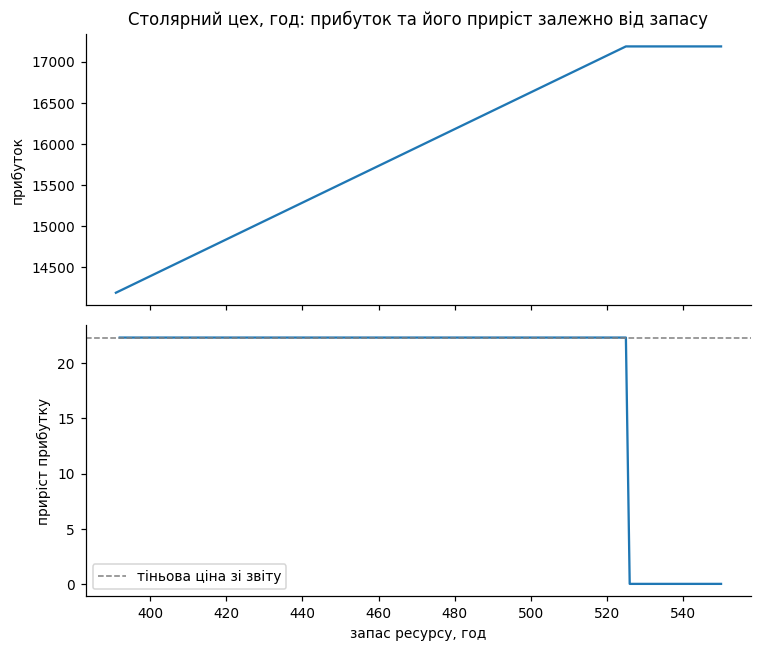

межа діапазону (допустиме збільшення): 134.0


In [8]:
# столярний цех - запас від базового значення і вище з кроком 1
запаси = np.arange(b[1], b[1] + 160, 1.0)
прибутки = []
for r in запаси:
    b_проб = b.copy()
    b_проб[1] = r
    res = linprog(-c, A_ub=A, b_ub=b_проб, bounds=[(0, None)] * len(c), method='highs')
    прибутки.append(-res.fun)
прибутки = np.array(прибутки)
прирости = np.diff(прибутки)  # нахил - приріст прибутку на кожен додатковий крок

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(7, 6), sharex=True)
ax1.plot(запаси, прибутки)
ax1.set_ylabel('прибуток')
ax1.set_title('Столярний цех, год: прибуток та його приріст залежно від запасу')

ax2.plot(запаси[1:], прирости)
ax2.axhline(22.33, color='gray', linestyle='--', linewidth=1, label='тіньова ціна зі звіту')
ax2.set_ylabel('приріст прибутку')
ax2.set_xlabel('запас ресурсу, год')
ax2.legend()
plt.tight_layout()
plt.show()

межа = запаси[np.argmax(прирости < 22)] - b[1]
print('межа діапазону (допустиме збільшення):', межа)


**Відповідь 5.2:** запас столярного цеху можна збільшувати на 134 одиниці (з 391 до 525 год) - на цій ділянці приріст прибутку сталий і дорівнює тіньовій ціні 22,33. Після 525 год нахил графіка приросту падає до 0 - злам відповідає базису, що змінився. Знайдена межа (134) повністю збігається з «допустимим збільшенням» зі звіту Excel.

---
# Етап 6. Рішення про закупівлю

Постачальник пропонує вам додатковий обсяг ресурсу — див. блок «ПРОПОЗИЦІЯ
ПОСТАЧАЛЬНИКА» у ваших даних.

### Завдання 6.1
Дайте відповідь директорові на три питання, спираючись на числа, а не на здоровий глузд:

1. **Брати чи не брати?** Порівняйте ціну пропозиції з тіньовою ціною.
2. **Скільки саме брати?** Постачальник пропонує більше, ніж вам потрібно.
3. **Скільки на цьому заробимо?** Порахуйте виграш і перевірте його прямим
   розв'язанням задачі з новим запасом.

In [9]:
# пропозиція постачальника - додатковий запас столярного цеху
тіньова_ціна = 22.33            # зі звіту Excel (найдорожчий ресурс)
ціна_пропозиції = V['ціна_пропозиції']
обсяг_пропозиції = V['обсяг_пропозиції']

print('тіньова ціна ресурсу:', тіньова_ціна)
print('ціна пропозиції постачальника:', ціна_пропозиції)

# 1) брати чи ні - порівнюємо ціни
if ціна_пропозиції < тіньова_ціна:
    print('ціна нижча за тіньову - купувати вигідно')
else:
    print('ціна вища за тіньову - купувати невигідно')

# 2) скільки має сенс брати - перевіряємо кілька обсягів прямим розв'язанням
for x in [0, 1, 10, 50, 134, обсяг_пропозиції]:
    b_проб = b.copy()
    b_проб[1] += x
    res = linprog(-c, A_ub=A, b_ub=b_проб, bounds=[(0, None)] * len(c), method='highs')
    приріст_прибутку = -res.fun - прибуток
    витрати = ціна_пропозиції * x
    чистий_виграш = приріст_прибутку - витрати
    print('x=%3d: приріст прибутку=%8.2f, витрати=%8.2f, чистий виграш=%8.2f'
          % (x, приріст_прибутку, витрати, чистий_виграш))


тіньова ціна ресурсу: 22.33
ціна пропозиції постачальника: 29.5
ціна вища за тіньову - купувати невигідно
x=  0: приріст прибутку=    0.00, витрати=    0.00, чистий виграш=    0.00
x=  1: приріст прибутку=   22.33, витрати=   29.50, чистий виграш=   -7.17
x= 10: приріст прибутку=  223.33, витрати=  295.00, чистий виграш=  -71.67
x= 50: приріст прибутку= 1116.67, витрати= 1475.00, чистий виграш= -358.33
x=134: приріст прибутку= 2992.67, витрати= 3953.00, чистий виграш= -960.33
x=268: приріст прибутку= 2992.67, витрати= 7906.00, чистий виграш=-4913.33


**Відповідь 6.1:**

* Брати чи ні і чому: ні, не варто. Тіньова ціна столярного цеху зі звіту - 22,33 грн за годину, а постачальник просить 29,5 грн за годину. Кожна куплена година дає менше, ніж коштує, тому купівля одразу збиткова - і невигідна лишається на всьому діапазоні, який пропонує постачальник (перевірила прямим розв'язанням для x = 0, 1, 10, 50, 134 і 268 - чистий виграш від'ємний і тільки падає зі збільшенням обсягу).
* Скільки одиниць має сенс купити і чому не більше: 0 одиниць. Уже перша куплена одиниця дає збиток 7,17 грн (22,33 - 29,5), а далі - гірше: після +134 год тіньова ціна цього ресурсу взагалі падає до нуля (це вже межа з відповіді 5.2), бо в план впирається інший ресурс.
* Очікуваний виграш: від'ємний за будь-якого обсягу - тобто виграшу немає, купівля веде до збитку.
* Перевірка прямим розв'язанням дала: ті самі висновки - чистий виграш (приріст прибутку мінус витрати на закупівлю) від'ємний для всіх перевірених обсягів (1, 10, 50, 134, 268 год) і стає дедалі гіршим.

---
# Етап 7. Перевірка розв'язку

### Завдання 7.1
Порахуйте дві величини:

* скільки виробів мають **ненульовий** випуск;
* скільки обмежень **зв'язні** (ресурс витрачено повністю).

Порівняйте.

In [10]:
план_arr = np.array(план)
використано = A @ план_arr   # скільки фактично витрачено кожного ресурсу

ненульових = int(np.sum(план_arr > 1e-6))
звязних = int(np.sum(np.isclose(використано, b, atol=1e-4)))

print('план:', [round(x, 2) for x in план])
print('використано ресурсів:', [round(x, 2) for x in використано])
print('запас ресурсів:      ', list(b))


план: [np.float64(0.0), np.float64(155.67), np.float64(0.0), np.float64(79.67)]
використано ресурсів: [np.float64(630.0), np.float64(391.0), np.float64(937.67), np.float64(470.67), np.float64(861.67)]
запас ресурсів:       [np.float64(630.0), np.float64(391.0), np.float64(1349.0), np.float64(811.0), np.float64(1085.0)]


In [11]:
assert ненульових is not None and звязних is not None, 'спершу порахуйте'
print('ненульових змінних: %s | зв’язних обмежень: %s' % (ненульових, звязних))
assert ненульових == звязних, ('числа не збіглися — це сигнал. Перевірте розв’язок '
                               'і поясніть причину в клітинці нижче')
print('Етап 7 пройдено')

ненульових змінних: 2 | зв’язних обмежень: 2
Етап 7 пройдено


**Відповідь 7.1:** числа збіглися - 2 ненульових вироби (Ray і Marlin) і 2 зв'язних обмеження (склопластик і столярний цех - саме ті, у яких тіньова ціна ненульова у звіті). Це не випадковість: у моделі 4 змінні, тому оптимум лежить у точці, яку задають рівно 4 активні умови - кожна це або "виріб = 0", або "ресурс вичерпано". Тому нульових виробів і зв'язних ресурсів завжди в сумі 4, а отже ненульових виробів стільки ж, скільки зв'язних ресурсів. Якби числа не збіглися, це означало б, що розв'язок вироджений (є альтернативний базис із тим самим прибутком) або що десь помилка в моделі чи обчисленні.

---
# Етап 8. Цілочисельність

Ваш оптимальний план містить дробові числа. Виготовити 63,3 виробу неможливо.

### Завдання 8.1
Порівняйте три варіанти:

1. розв'язок без умови цілочисельності (уже маєте);
2. **округлений** план — округліть кожне значення до цілого й перевірте, чи він
   узагалі допустимий і скільки прибутку дає;
3. справжній **цілочисельний** оптимум — розв'яжіть задачу з умовою, що всі змінні цілі
   (`cat='Integer'` у PuLP або `integrality=1` у `linprog`).

In [12]:
# 1) без умови цілочисельності - уже маємо (план, прибуток)
print('без умови цілочисельності:', [round(x, 2) for x in план], '| прибуток', round(прибуток, 2))

# 2) округлений план - округлюємо кожне значення і перевіряємо допустимість
округлений = np.round(план)
використано_окр = A @ округлений
допустимий_окр = bool(np.all(використано_окр <= b + 1e-9))
прибуток_окр = c @ округлений

print('округлений:', округлений, '| використано:', використано_окр,
      '| допустимий:', допустимий_окр, '| прибуток', прибуток_окр)

# 3) справжній цілочисельний оптимум
res_int = linprog(-c, A_ub=A, b_ub=b, bounds=[(0, None)] * len(c),
                   integrality=1, method='highs')
план_int = res_int.x
прибуток_int = -res_int.fun

print('цілочисельний оптимум:', план_int, '| прибуток', прибуток_int)


без умови цілочисельності: [np.float64(0.0), np.float64(155.67), np.float64(0.0), np.float64(79.67)] | прибуток 14192.33
округлений: [  0. 156.   0.  80.] | використано: [632. 392. 940. 472. 864.] | допустимий: False | прибуток 14232.0
цілочисельний оптимум: [  0. 156.   0.  79.] | прибуток 14175.0


**Відповідь 8.1:**

| Варіант | План | Прибуток | Допустимий? |
|---|---|---|---|
| без умови цілочисельності | (0; 155,67; 0; 79,67) | 14192,33 | так (дробовий, але формально в межах) |
| округлений | (0; 156; 0; 80) | 14232,00 | **ні** - перевищує запас склопластику (632 > 630) і столярного цеху (392 > 391) |
| цілочисельний оптимум | (0; 156; 0; 79) | 14175,00 | так |

**Висновок:** округлювати не можна - округлений план виглядає навіть вигіднішим на папері (14232 замість 14175), але насправді недопустимий: простим округленням вгору легко "з'їсти" ресурс, якого й так не вистачало впритул (склопластик і столярний цех були витрачені повністю ще в LP-розв'язку). Справжній цілочисельний оптимум (14175) трохи гірший за дробовий LP-розв'язок (14192,33) - це і є "ціна цілочисельності": втрата прибутку через те, що план мусить складатися з цілих виробів. Отже, для отримання коректного цілого плану треба розв'язувати задачу саме з умовою цілочисельності, а не округляти LP-розв'язок.

---
# ЧАСТИНА 2. Транспортна задача

Друга частина виконується самостійно. Тут ви застосуєте ту саму методику до задачі
іншого класу — і побачите, що вона поводиться інакше.

# Етап 9. Ваші дані

### Завдання 9.1
Сформуйте власні дані:

* **три міста-постачальники** — за першими трьома літерами вашого **прізвища**;
* **чотири міста-споживачі** — за першими чотирма літерами вашого **імені**;
* **матриця відстаней 3 × 4** — реальні відстані автошляхами за Google Maps, у кілометрах;
* **запаси і попит** — невеликі цілі числа, підберіть так, щоб **сумарний запас
  дорівнював сумарному попиту**.

> Якщо на якусь літеру міста немає — беріть наступну літеру прізвища чи імені.
> Якщо сумарний запас не дорівнює попиту, задача з обмеженнями-рівностями
> **не матиме розв'язку взагалі**. Це не помилка Python — це властивість моделі.

In [13]:
# ВАШ КОД - впишіть свої дані
# постачальники - перші 3 літери прізвища (Козак): К, О, З
# споживачі - перші 4 літери імені (Наталія: Н,А,Т,А - друга "А" повторюється,
# тому четверту літеру взяла наступну унікальну - Л)
постачальники = ['Київ', 'Одеса', 'Запоріжжя']
споживачі     = ['Ніжин', 'Ананьїв', 'Тернопіль', 'Львів']

# відстані автошляхами, км (Google Maps)
D = np.array([
    [158, 347, 446, 540],   # Київ
    [619, 178, 663, 796],   # Одеса
    [527, 517, 881, 1007],  # Запоріжжя
])

запас = [40, 35, 25]           # Київ, Одеса, Запоріжжя
попит = [30, 20, 25, 25]       # Ніжин, Ананьїв, Тернопіль, Львів

assert len(постачальники) == 3 and len(споживачі) == 4, 'потрібно 3 постачальники і 4 споживачі'
assert D.shape == (3, 4), 'матриця відстаней має бути 3 x 4'
assert sum(запас) == sum(попит), 'сумарний запас має дорівнювати сумарному попиту'
pd.DataFrame(D, index=постачальники, columns=споживачі)


,Ніжин,Ананьїв,Тернопіль,Львів
Київ,158,347,446,540
Одеса,619,178,663,796
Запоріжжя,527,517,881,1007


---
# Етап 10. Розв'язання транспортної задачі

### Завдання 10.1
Розв'яжіть задачу **двічі різними засобами**: наприклад `pulp` і
`scipy.optimize.linprog(method='highs')`. Обмеження — рівності.

Для кожного розв'язку виведіть: оптимальний план перевезень, сумарну вартість
і **тіньові ціни всіх обмежень**.

In [14]:
# ВАШ КОД — розв'язок 1: pulp
import pulp

x = [[pulp.LpVariable(f'x_{i}_{j}', lowBound=0) for j in range(4)] for i in range(3)]

задача = pulp.LpProblem('перевезення', pulp.LpMinimize)
задача += pulp.lpSum(D[i][j] * x[i][j] for i in range(3) for j in range(4))

supply_обм = []
for i in range(3):
    обм = pulp.lpSum(x[i][j] for j in range(4)) == запас[i]
    задача += обм
    supply_обм.append(обм)

demand_обм = []
for j in range(4):
    обм = pulp.lpSum(x[i][j] for i in range(3)) == попит[j]
    задача += обм
    demand_обм.append(обм)

задача.solve(pulp.PULP_CBC_CMD(msg=0))

план_pulp = np.array([[x[i][j].value() for j in range(4)] for i in range(3)])
вартість_pulp = pulp.value(задача.objective)
тіньові_supply_pulp = [обм.pi for обм in supply_обм]
тіньові_demand_pulp = [обм.pi for обм in demand_обм]

print('статус:', pulp.LpStatus[задача.status])
print('план перевезень:')
print(pd.DataFrame(план_pulp, index=постачальники, columns=споживачі))
print('сумарна вартість:', вартість_pulp)
print('тіньові ціни постачальників:', dict(zip(постачальники, тіньові_supply_pulp)))
print('тіньові ціни споживачів:    ', dict(zip(споживачі, тіньові_demand_pulp)))


статус: Optimal
план перевезень:
           Ніжин  Ананьїв  Тернопіль  Львів
Київ         5.0      0.0       10.0   25.0
Одеса        0.0     20.0       15.0    0.0
Запоріжжя   25.0      0.0        0.0    0.0
сумарна вартість: 45430.0
тіньові ціни постачальників: {'Київ': 158.0, 'Одеса': 375.0, 'Запоріжжя': 527.0}
тіньові ціни споживачів:     {'Ніжин': 0.0, 'Ананьїв': -197.0, 'Тернопіль': 288.0, 'Львів': 382.0}


In [15]:
# ВАШ КОД — розв'язок 2: scipy.optimize.linprog
n_s, n_c = 3, 4
c_вект = D.flatten()

A_eq, b_eq = [], []
for i in range(n_s):                       # обмеження по запасу
    рядок = np.zeros(n_s * n_c)
    рядок[i * n_c:(i + 1) * n_c] = 1
    A_eq.append(рядок); b_eq.append(запас[i])
for j in range(n_c):                        # обмеження по попиту
    рядок = np.zeros(n_s * n_c)
    for i in range(n_s):
        рядок[i * n_c + j] = 1
    A_eq.append(рядок); b_eq.append(попит[j])

res = linprog(c_вект, A_eq=A_eq, b_eq=b_eq, bounds=[(0, None)] * (n_s * n_c), method='highs')

план_lp = res.x.reshape(n_s, n_c)
вартість_lp = res.fun
тіньові_lp = res.eqlin.marginals
тіньові_supply_lp = тіньові_lp[:n_s]
тіньові_demand_lp = тіньові_lp[n_s:]

print('план перевезень:')
print(pd.DataFrame(план_lp, index=постачальники, columns=споживачі))
print('сумарна вартість:', вартість_lp)
print('тіньові ціни постачальників:', dict(zip(постачальники, тіньові_supply_lp)))
print('тіньові ціни споживачів:    ', dict(zip(споживачі, тіньові_demand_lp)))


план перевезень:
           Ніжин  Ананьїв  Тернопіль  Львів
Київ         5.0      0.0       10.0   25.0
Одеса        0.0     20.0       15.0    0.0
Запоріжжя   25.0      0.0        0.0    0.0
сумарна вартість: 45430.0
тіньові ціни постачальників: {'Київ': np.float64(-0.0), 'Одеса': np.float64(217.0), 'Запоріжжя': np.float64(369.0)}
тіньові ціни споживачів:     {'Ніжин': np.float64(158.0), 'Ананьїв': np.float64(-39.0), 'Тернопіль': np.float64(446.0), 'Львів': np.float64(540.0)}


### Завдання 10.2 — головне питання цієї частини
Порівняйте два набори тіньових цін.

**Сумарна вартість у двох розв'язувачів однакова. А тіньові ціни?**

Якщо вони різні — це не помилка. Знайдіть закономірність: подивіться на різницю
між відповідними значеннями окремо для постачальників і окремо для споживачів.

In [16]:
# ВАШ КОД — порівняння
print('вартість pulp:   ', вартість_pulp)
print('вартість linprog:', вартість_lp)
print()
print('тіньові постачальників, pulp:   ', тіньові_supply_pulp)
print('тіньові постачальників, linprog:', list(тіньові_supply_lp))
print('різниця:', np.array(тіньові_supply_pulp) - тіньові_supply_lp)
print()
print('тіньові споживачів, pulp:   ', тіньові_demand_pulp)
print('тіньові споживачів, linprog:', list(тіньові_demand_lp))
print('різниця:', np.array(тіньові_demand_pulp) - тіньові_demand_lp)


вартість pulp:    45430.0
вартість linprog: 45430.0

тіньові постачальників, pulp:    [158.0, 375.0, 527.0]
тіньові постачальників, linprog: [np.float64(-0.0), np.float64(217.0), np.float64(369.0)]
різниця: [158. 158. 158.]

тіньові споживачів, pulp:    [0.0, -197.0, 288.0, 382.0]
тіньові споживачів, linprog: [np.float64(158.0), np.float64(-39.0), np.float64(446.0), np.float64(540.0)]
різниця: [-158. -158. -158. -158.]


**Відповідь 10.2:**

* Вартість у двох розв'язувачів: однакова - 45430 (у обох).
* Тіньові ціни збіглися чи ні: ні, різні: постачальники pulp = [158, 375, 527], лінпрог = [0, 217, 369]; споживачі pulp = [0, -197, 288, 382], лінпрог = [158, -39, 446, 540]. План перевезень при цьому в обох однаковий.
* Яку закономірність ви побачили в різниці: різниця постійна - у постачальників pulp на +158 більша за linprog, у споживачів рівно на -158 менша. Тобто один розв'язувач додав константу 158 до всіх тіньових цін постачальників і відняв ту саму константу від усіх тіньових цін споживачів. Це наслідок того, що в збалансованій транспортній задачі одне з 7 обмежень (3 запаси + 4 попити) залежне від решти (сума запасів = сумі попитів), тому система рівнянь для тіньових цін має на одну умову менше, ніж невідомих - розв'язок визначений лише з точністю до довільної константи, яку кожен солвер обирає по-своєму (наприклад, поклавши тіньову ціну першого обмеження нулем).
* Що це означає для того, хто збирається ухвалювати рішення за цим звітом: абсолютні значення тіньових цін тут не можна порівнювати "в лоб", якщо звіти зроблені різними солверами - вони можуть відрізнятись на однакову константу. А от різниці між тіньовими цінами (наприклад, наскільки один постачальник "дорожчий" за іншого) і план перевезень - надійні й однакові в обох розв'язках.

---
# Етап 11. Перевірка розв'язку — і чому вона тут не працює

### Завдання 11.1
Порахуйте для транспортної задачі те саме, що на етапі 7:

* кількість **ненульових перевезень**;
* кількість **зв'язних обмежень**.

Порівняйте з числом `3 + 4 = 7` — кількістю обмежень у задачі.

In [17]:
# ВАШ КОД
план_t = план_lp                       # розв'язок linprog з етапу 10
ненульових_перевезень = int(np.sum(план_t > 1e-6))

використано_t = np.concatenate([план_t.sum(axis=1), план_t.sum(axis=0)])   # постачальники + споживачі
зв_язних_обмежень = int(np.sum(np.isclose(використано_t, np.concatenate([запас, попит]), atol=1e-4)))

print('ненульових перевезень:', ненульових_перевезень)
print('зв\'язних обмежень:', зв_язних_обмежень, 'з', 3 + 4)
print('m + n - 1 =', 3 + 4 - 1)

ненульових перевезень: 6
зв'язних обмежень: 7 з 7
m + n - 1 = 6


**Відповідь 11.1:**

* Ненульових перевезень: 6 - Київ→Ніжин 5, Київ→Тернопіль 10, Київ→Львів 25, Одеса→Ананьїв 20, Одеса→Тернопіль 15, Запоріжжя→Ніжин 25.
* Зв'язних обмежень: 7 з 7 - усі обмеження виконані як рівності.
* Чому в транспортній задачі зв'язними виявляються всі обмеження: тому що всі вони записані як рівності (запас має бути повністю вивезений, попит повністю задоволений), а не як нерівності. У ЛП-задачі з "≤" зв'язним було б лише те обмеження, яке справді вичерпано; тут кожне обмеження зв'язне за побудовою.
* На скільки ненульових перевезень менше і чому саме на стільки: на 1 менше, ніж обмежень (6 проти 7). Це m + n − 1 = 3 + 4 − 1 = 6 - класична властивість невиродженого опорного розв'язку транспортної задачі. Одне обмеження завжди залежне від решти: сума всіх запасів дорівнює сумі всіх попитів, тому якщо 6 з 7 рівнянь виконані, сьоме виконується автоматично. Тобто "зайве" обмеження не потребує окремого ненульового перевезення, тому ненульових на одне менше, ніж обмежень.

### Завдання 11.2 — візуалізація
Побудуйте дві теплові карти поруч: матрицю відстаней і матрицю оптимальних перевезень.
Підпишіть осі та значення в комірках.

*За бажанням (не оцінюється): граф маршрутів через `networkx`, де товщина ребра
пропорційна обсягу перевезення.*

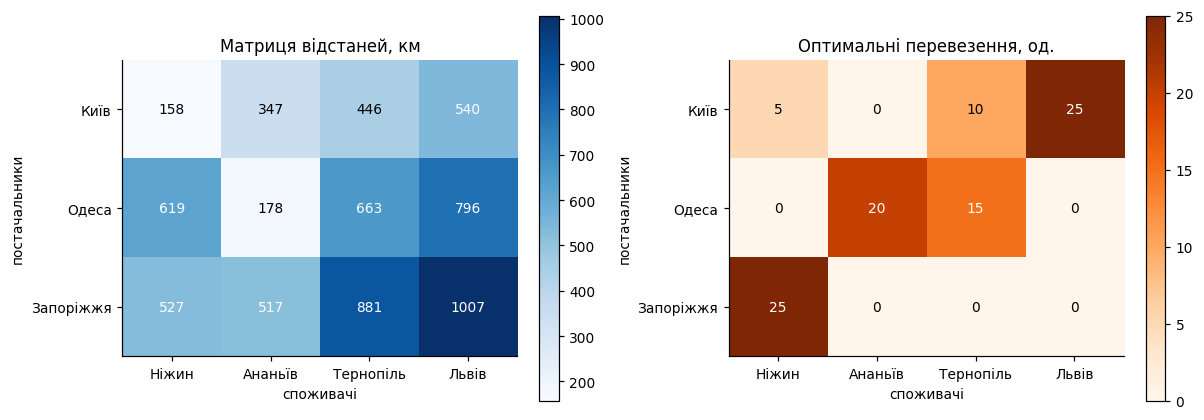

In [18]:
# теплові карти: відстані і оптимальні перевезення поруч
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))

for ax, матриця, заголовок, cmap, fmt in [
    (ax1, D, 'Матриця відстаней, км', 'Blues', '{:.0f}'),
    (ax2, план_t, 'Оптимальні перевезення, од.', 'Oranges', '{:.0f}'),
]:
    im = ax.imshow(матриця, cmap=cmap)
    ax.set_xticks(range(len(споживачі)))
    ax.set_xticklabels(споживачі)
    ax.set_yticks(range(len(постачальники)))
    ax.set_yticklabels(постачальники)
    ax.set_xlabel('споживачі')
    ax.set_ylabel('постачальники')
    ax.set_title(заголовок)
    for i in range(матриця.shape[0]):
        for j in range(матриця.shape[1]):
            ax.text(j, i, fmt.format(матриця[i, j]), ha='center', va='center',
                    color='white' if матриця[i, j] > матриця.max() / 2 else 'black')
    fig.colorbar(im, ax=ax, fraction=0.046)

plt.tight_layout()
plt.show()


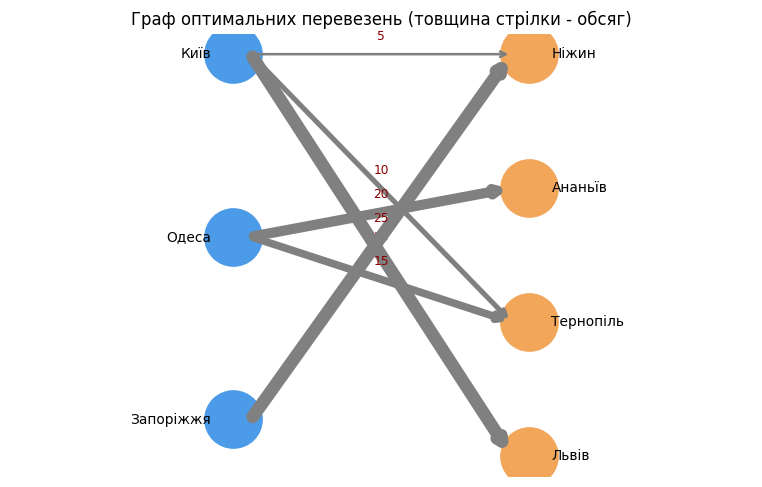

In [19]:
# граф маршрутів: товщина ребра пропорційна обсягу перевезення
import networkx as nx

G = nx.DiGraph()
for i, п in enumerate(постачальники):
    for j, с in enumerate(споживачі):
        if план_t[i][j] > 1e-6:
            G.add_edge(п, с, weight=план_t[i][j])

pos = {}
for k, п in enumerate(постачальники):
    pos[п] = (0, -k * 1.5)
for k, с in enumerate(споживачі):
    pos[с] = (2, -k * 1.1)

fig, ax = plt.subplots(figsize=(7, 4.5))
for п in постачальники:
    ax.scatter(*pos[п], s=1400, color='#4C9BE8', zorder=3)
    ax.text(pos[п][0] - 0.15, pos[п][1], п, ha='right', va='center', fontsize=9)
for с in споживачі:
    ax.scatter(*pos[с], s=1400, color='#F2A65A', zorder=3)
    ax.text(pos[с][0] + 0.15, pos[с][1], с, ha='left', va='center', fontsize=9)

for u, v, d in G.edges(data=True):
    x0, y0 = pos[u]
    x1, y1 = pos[v]
    ax.annotate('', xy=(x1 - 0.12, y1), xytext=(x0 + 0.12, y0),
                arrowprops=dict(arrowstyle='->', lw=d['weight'] / 3, color='gray'))
    ax.text((x0 + x1) / 2, (y0 + y1) / 2 + 0.12, str(int(d['weight'])),
            ha='center', fontsize=8, color='darkred')

ax.set_xlim(-1.5, 3.5)
ax.set_axis_off()
ax.set_title('Граф оптимальних перевезень (товщина стрілки - обсяг)')
plt.tight_layout()
plt.show()


**Висновок:** план дуже "розріджений": з 12 можливих маршрутів використано лише 6. Запоріжжя відправляє весь свій вантаж лише в Ніжин, а найдальші маршрути (Запоріжжя→Тернопіль, Запоріжжя→Львів, Одеса→Львів, Одеса→Ніжин) не використовуються взагалі.

---
# Етап 12. Декларація про використання інструментів штучного інтелекту

Користуватися мовними моделями **дозволено**. Обов'язковою є прозорість.
Порушенням є не використання інструмента, а нездатність пояснити власний код
і власні числа на захисті.

Для кожного етапу оберіть одне: `'ні'`, `'синтаксис'`, `'код, перевірено'`,
`'текст, перероблено'`, `'текст, як є'`.

In [20]:
ІНСТРУМЕНТИ_ШІ = 'Claude (Claude Code, Sonnet 5)'     # напр. 'ChatGPT' або 'не використовував'

ДЕКЛАРАЦІЯ = {
    'етап 1, формалізація моделі':          'текст, перероблено',
    'етап 2, побудова моделі в Excel':      'текст, перероблено',
    'етап 3, код на Python':                'код, перевірено',
    'етапи 4–5, читання та перевірка звіту': 'код, перевірено',
    'етап 6, рішення про закупівлю':        'текст, перероблено',
    'етапи 7–8, перевірка та цілочисельність': 'код, перевірено',
    'етапи 9–11, транспортна задача':       'код, перевірено',
}

# Що саме ви перевірили за згенерованим кодом чи текстом — конкретно.
ЩО_ПЕРЕВІРЕНО = (
    "Перевірила, що план Excel (Ray 155,67; Marlin 79,67) збігається з linprog і прибутком 14192,33; "
    "тіньову ціну столярного цеху 22,33 підтвердила прямим перерахунком (+1 год дає +22,33); "
    "межу 134 - перебором запасу з кроком 1; "
    "закупівлю за 29,5 відкинула, перевіривши чистий виграш розв'язанням для кількох обсягів; "
    "цілочисельний розв'язок порівняла з округленим (округлений недопустимий); "
    "транспортну задачу розв'язала pulp і linprog - вартість 45430 збіглася, різниця тіньових цін - стала константа 158."
)

# True означає: я можу пояснити кожен рядок свого коду, відтворити будь-яке число
# цієї роботи та внести зміни в модель на вимогу під час захисту.
ПІДТВЕРДЖУЮ = True   # змінити на True, коли ви самі можете пояснити кожен рядок


In [21]:
# --- перевірка повноти декларації: клітинку не редагувати --------------------
ДОЗВОЛЕНІ = {'ні', 'синтаксис', 'код, перевірено', 'текст, перероблено', 'текст, як є'}
assert ІНСТРУМЕНТИ_ШІ.strip(), 'Вкажіть інструменти або напишіть «не використовував»'
порожні = [k for k, v in ДЕКЛАРАЦІЯ.items() if not str(v).strip()]
assert not порожні, 'Не заповнено: %s' % '; '.join(порожні)
чужі = {v for v in ДЕКЛАРАЦІЯ.values() if v not in ДОЗВОЛЕНІ}
assert not чужі, 'Недопустимі значення: %s' % ', '.join(sorted(чужі))
assert len(ЩО_ПЕРЕВІРЕНО.strip()) >= 120, ('Опишіть конкретніше (зараз %d символів, '
                                           'потрібно щонайменше 120)' % len(ЩО_ПЕРЕВІРЕНО.strip()))
assert ПІДТВЕРДЖУЮ is True, 'Підтвердьте, що можете пояснити власний код на захисті'
print('ДЕКЛАРАЦІЯ ПРО ВИКОРИСТАННЯ ІНСТРУМЕНТІВ ШІ')
print('=' * 78)
print('%-42s %s' % ('автор:', ПІБ))
print('%-42s %s' % ('інструменти:', ІНСТРУМЕНТИ_ШІ))
print('-' * 78)
for k, v in ДЕКЛАРАЦІЯ.items():
    print('%-42s %s' % (k + ':', v))
print('-' * 78)
print(ЩО_ПЕРЕВІРЕНО)

ДЕКЛАРАЦІЯ ПРО ВИКОРИСТАННЯ ІНСТРУМЕНТІВ ШІ
автор:                                     Козак Наталія Володимирівна
інструменти:                               Claude (Claude Code, Sonnet 5)
------------------------------------------------------------------------------
етап 1, формалізація моделі:               текст, перероблено
етап 2, побудова моделі в Excel:           текст, перероблено
етап 3, код на Python:                     код, перевірено
етапи 4–5, читання та перевірка звіту:     код, перевірено
етап 6, рішення про закупівлю:             текст, перероблено
етапи 7–8, перевірка та цілочисельність:   код, перевірено
етапи 9–11, транспортна задача:            код, перевірено
------------------------------------------------------------------------------
Перевірила, що план Excel (Ray 155,67; Marlin 79,67) збігається з linprog і прибутком 14192,33; тіньову ціну столярного цеху 22,33 підтвердила прямим перерахунком (+1 год дає +22,33); межу 134 - перебором запасу з кроком 1; закупів

---
# Крок 13. Фінальна самоперевірка

In [22]:
перевірки = {
    'ПІБ і варіант заповнено':            bool(ПІБ) and 1 <= ВАРІАНТ <= 30,
    'Excel і Python дали однаковий план': abs(прибуток - EXCEL_ПРИБУТОК) < 0.5,
    'перевірку «ненульові = зв’язні» зроблено': ненульових == звязних,
    'дані транспортної задачі введено':   len(постачальники) == 3 and len(споживачі) == 4,
    'баланс запасів і попиту':            sum(запас) == sum(попит),
    'декларацію заповнено':               bool(ІНСТРУМЕНТИ_ШІ.strip()) and ПІДТВЕРДЖУЮ is True,
}
for k, v in перевірки.items():
    print(('OK   ' if v else 'НЕ ОК') + '  ' + k)
if all(перевірки.values()):
    print('\nТехнічна частина виконана.')
    print('Переконайтеся, що заповнені ВСІ клітинки з відповідями,')
    print('і виконайте Kernel → Restart & Run All перед здачею.')

OK     ПІБ і варіант заповнено
OK     Excel і Python дали однаковий план
OK     перевірку «ненульові = зв’язні» зроблено
OK     дані транспортної задачі введено
OK     баланс запасів і попиту
OK     декларацію заповнено

Технічна частина виконана.
Переконайтеся, що заповнені ВСІ клітинки з відповідями,
і виконайте Kernel → Restart & Run All перед здачею.
